# Hospital appointment no-show prediction — EDA, leakage review and model results
**Prediction unit:** one booked appointment · **Prediction time:** the moment of booking · **Target:** `no_show` (1 = patient did not attend) · **Decision:** which bookings get a *human-reviewed* reminder call.

Run `python -m noshow.train` first (creates the cleaned data and `reports/metrics.json`). This notebook only reads those outputs and the `noshow` package.

In [1]:
import sys, json; sys.path.insert(0, '../src')
import pandas as pd, numpy as np
from IPython.display import Image, display
from noshow import config
df = pd.read_csv(config.DATA_PROCESSED/config.CLEAN_FILENAME, parse_dates=['scheduled_ts','appointment_day'])
m = json.load(open(config.METRICS_PATH)); dq = m['data_quality']
print('data source:', dq['data_source']); print({k:dq[k] for k in ['rows_raw','rows_clean','invalid_age_rows_removed','appointment_before_booking_rows_removed','dropped_columns']})
df.head()

data source: kaggle
{'rows_raw': 110527, 'rows_clean': 110516, 'invalid_age_rows_removed': 6, 'appointment_before_booking_rows_removed': 5, 'dropped_columns': ['Hipertension', 'Diabetes', 'Alcoholism', 'Handcap', 'SMS_received']}


,patient_id,appointment_id,gender,scheduled_ts,appointment_day,age,neighbourhood,scholarship,scheduled_day,no_show,...,prior_no_show_rate,days_since_last_appointment,has_history,lead_days,log_lead_days,same_day,scheduled_hour,scheduled_weekday,appointment_weekday,split
0,8.322564e+14,5030230,F,2015-11-10 07:13:56,2016-05-04,51,RESISTÊNCIA,0,2015-11-10,0,...,NaN,NaN,0,176,5.176150,0,7,Tuesday,Wednesday,train
1,9.163747e+13,5122866,M,2015-12-03 08:17:28,2016-05-02,34,VILA RUBIM,0,2015-12-03,1,...,NaN,NaN,0,151,5.023881,0,8,Thursday,Monday,train
2,1.216587e+12,5134197,F,2015-12-07 10:40:59,2016-06-03,27,SÃO CRISTÓVÃO,1,2015-12-07,1,...,NaN,NaN,0,179,5.192957,0,10,Monday,Friday,test
3,3.189960e+13,5134220,F,2015-12-07 10:42:42,2016-06-03,48,MARUÍPE,0,2015-12-07,0,...,NaN,NaN,0,179,5.192957,0,10,Monday,Friday,test
4,9.582232e+12,5134223,F,2015-12-07 10:43:01,2016-06-03,80,SÃO CRISTÓVÃO,0,2015-12-07,0,...,NaN,NaN,0,179,5.192957,0,10,Monday,Friday,test


## 1. Data quality and class balance

In [2]:
pd.Series(dq['split_rows']).to_frame('rows').join(pd.Series(dq['split_no_show_rate']).rename('no_show_rate')).join(pd.DataFrame(dq['split_date_ranges'],index=['first_day','last_day']).T)

,rows,no_show_rate,first_day,last_day
train,63529,0.2094,2016-04-29,2016-05-19
test,26449,0.1846,2016-06-01,2016-06-08
val,20538,0.2008,2016-05-20,2016-05-31


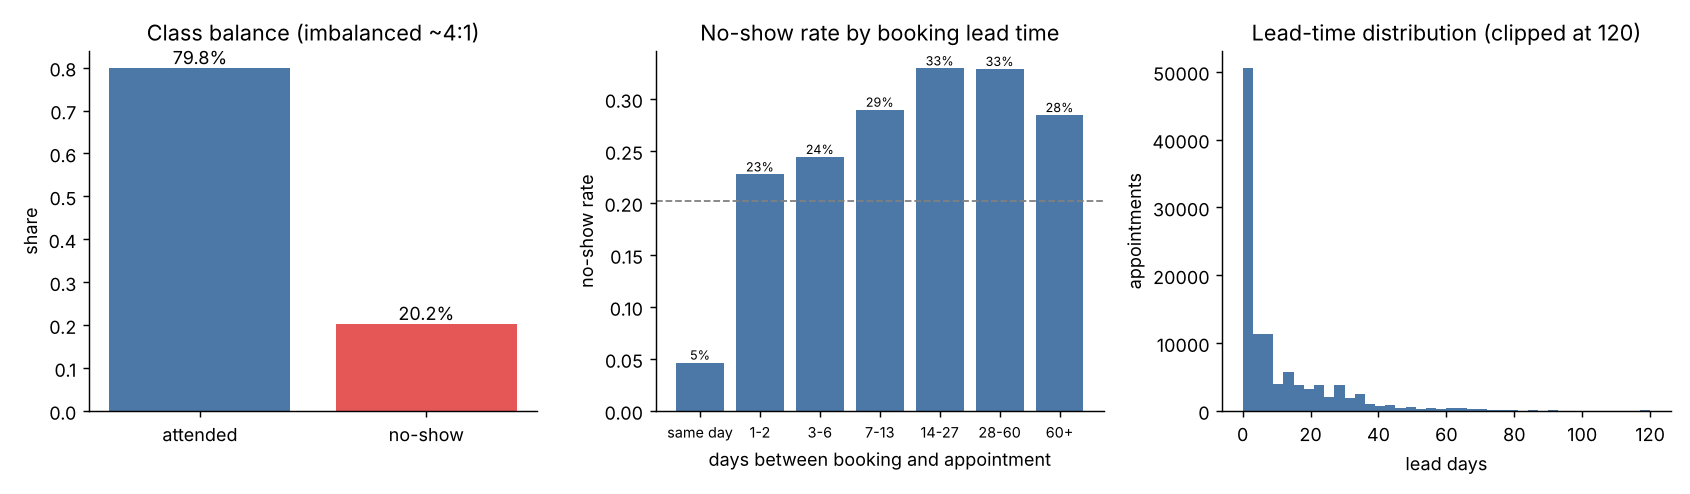

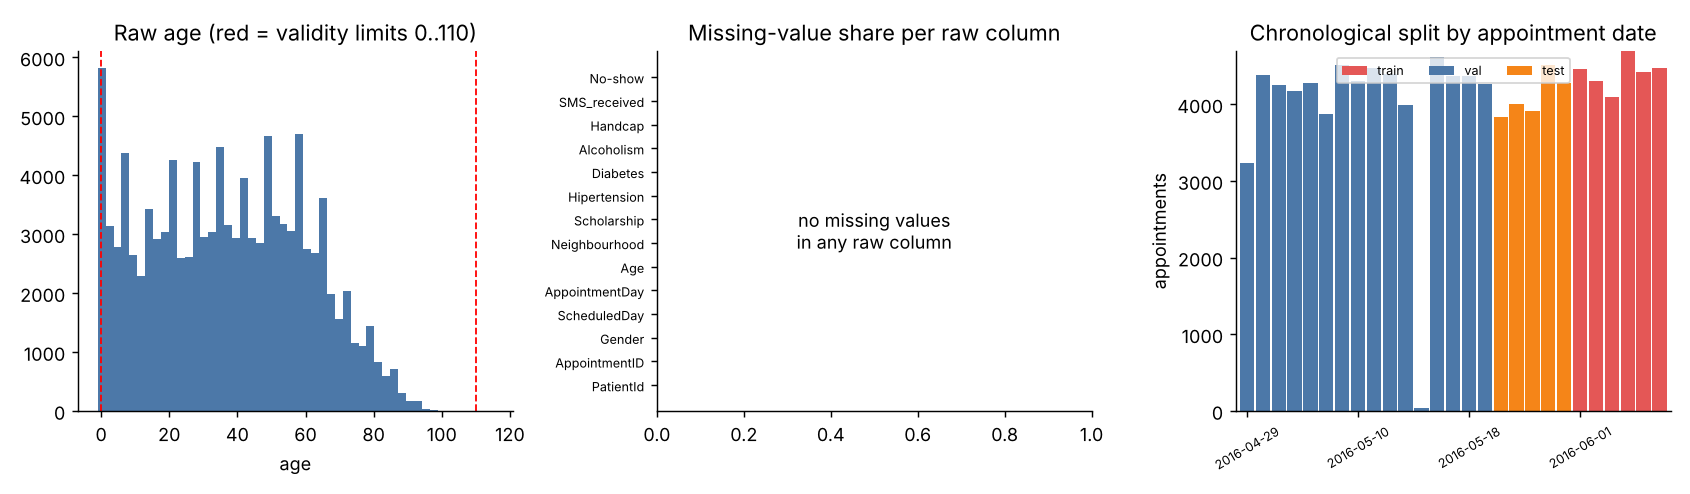

In [3]:
display(Image(str(config.FIG_DIR/'01_target_and_lead_time.png'))); display(Image(str(config.FIG_DIR/'04_data_quality_and_split.png')))

The target is imbalanced (~1 in 5 (20%) no-shows). Handled with class weights during training plus probability calibration afterwards; accuracy is never used as the headline metric.

## 2. What drives no-shows?

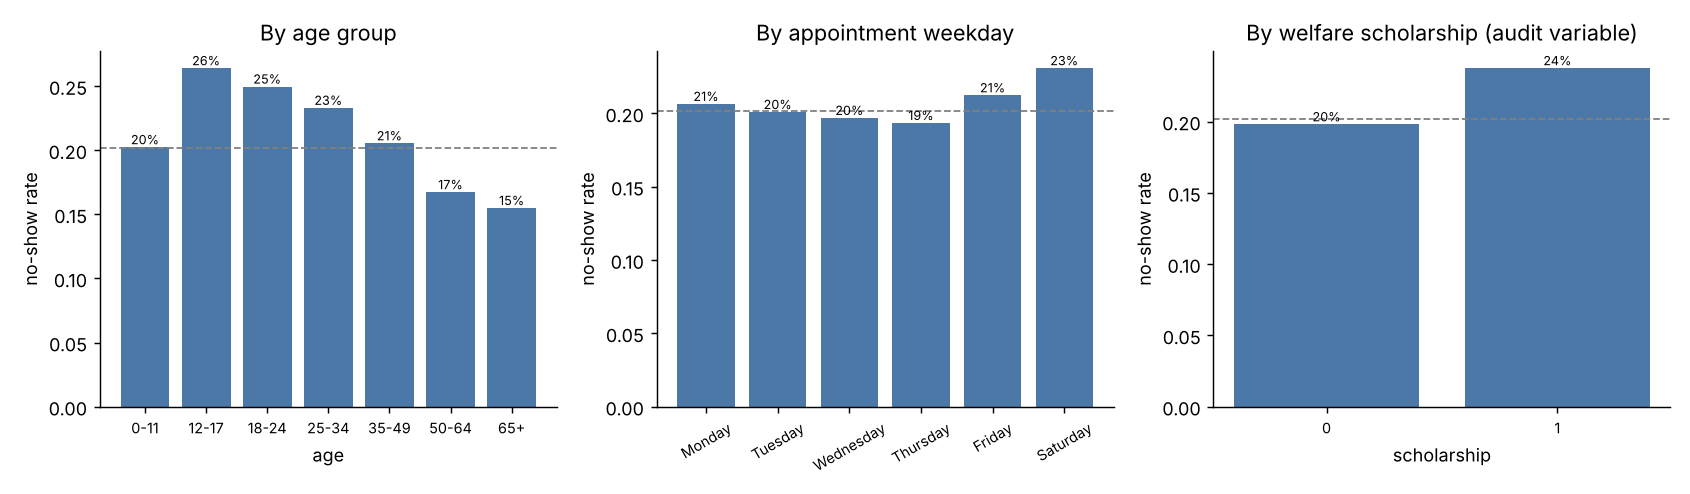

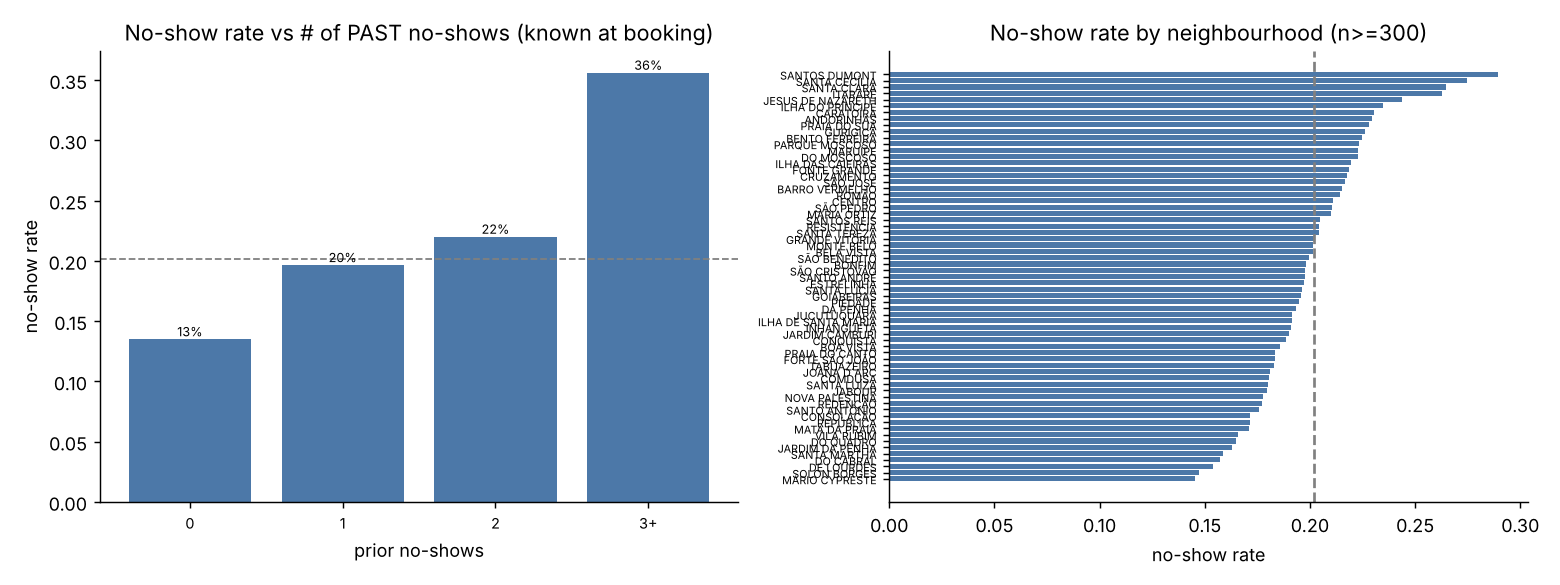

In [4]:
display(Image(str(config.FIG_DIR/'02_age_weekday_scholarship.png'))); display(Image(str(config.FIG_DIR/'03_history_neighbourhood.png')))

## 3. Leakage review

In [5]:
eda = json.load(open(config.REPORTS_DIR/'eda_summary.json'))
print(json.dumps(eda['leakage_review'], indent=2)); pd.Series(eda['single_feature_auc_train']).to_frame('single-feature AUC (train)')

{
  "max_single_feature_auc": 0.7003,
  "note": "No single feature has an implausibly high AUC (>0.9), the signature of target leakage.",
  "excluded_post_booking": [
    "SMS_received"
  ],
  "excluded_sensitive_clinical": [
    "Hipertension",
    "Diabetes",
    "Alcoholism",
    "Handcap"
  ],
  "audit_only": [
    "gender"
  ],
  "history_rule": "prior_* features count only appointments whose DATE is strictly before the booking date"
}


,single-feature AUC (train)
lead_days,0.7003
log_lead_days,0.7003
same_day,0.6672
scheduled_hour,0.5488
age,0.5449
prior_appointments,0.5322
has_history,0.5320
scholarship,0.5117
days_since_last_appointment,0.5019
prior_no_shows,0.5001


* `SMS_received` is **excluded**: the SMS is sent *after* booking (it is the intervention we are trying to plan), only for longer lead times.
* Clinical columns (`Hipertension`, `Diabetes`, `Alcoholism`, `Handcap`) are dropped on load — out of scope by the brief.
* `gender` is kept for the fairness audit only, never as a model input.
* History features count only appointments whose date is strictly before the booking date (unit-tested, including a "time-travel" test).
* No single feature has a suspiciously high AUC.

## 4. Baselines vs candidate models (held-out test, thresholds picked on validation)

In [6]:
rows=[]
for k,v in m['baselines'].items():
    if 'precision' in v: rows.append({'model':k,**{x:v[x] for x in ['precision','recall','f1','roc_auc','pr_auc','cost_per_appointment']}})
for k,v in m['models'].items(): rows.append({'model':k,**{x:v[x] for x in ['precision','recall','f1','roc_auc','pr_auc','cost_per_appointment']}})
pd.DataFrame(rows).set_index('model')

,precision,recall,f1,roc_auc,pr_auc,cost_per_appointment
model,,,,,,
never_flag,0.0000,0.0000,0.0000,0.5000,0.1846,0.7383
flag_everyone,0.1846,1.0000,0.3116,0.5000,0.1846,0.8154
lead_time_rule,0.2600,0.9236,0.4057,0.6914,0.2819,0.5417
logistic_regression,0.2813,0.7745,0.4127,0.7171,0.3124,0.5317
random_forest,0.2932,0.6692,0.4077,0.7187,0.3141,0.5420
hist_gradient_boosting,0.3031,0.6884,0.4209,0.7291,0.3296,0.5221


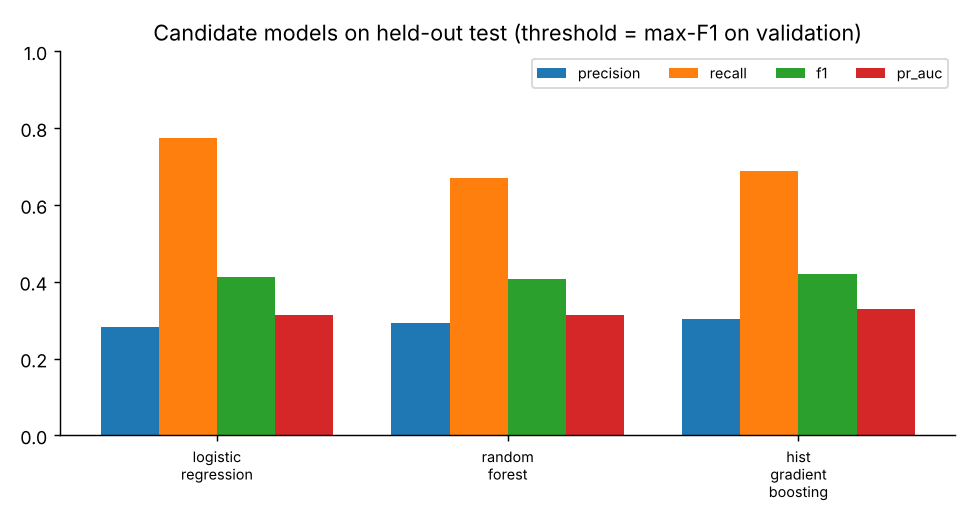

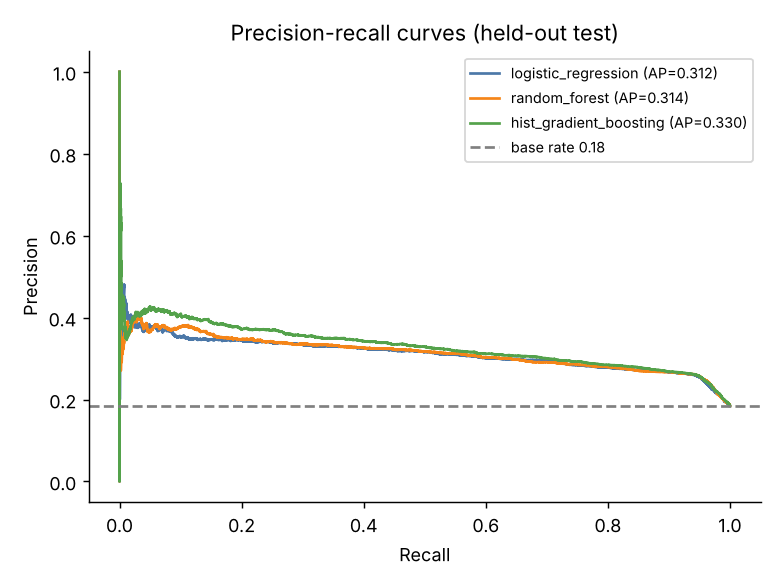

In [7]:
display(Image(str(config.FIG_DIR/'10_model_comparison.png'))); display(Image(str(config.FIG_DIR/'05_pr_curves.png')))

## 5. Final model: calibration, threshold and cost

In [8]:
f=m['final_model']; print(f['name'], f['calibration']); print(json.dumps(f['test'],indent=1))

hist_gradient_boosting Platt scaling (logistic regression on logit score) fitted on the validation set
{
 "threshold": 0.1751,
 "precision": 0.2744,
 "recall": 0.8689,
 "f1": 0.4171,
 "flag_rate": 0.5844,
 "tn": 10351,
 "fp": 11216,
 "fn": 640,
 "tp": 4242,
 "business_cost": 13776.0,
 "cost_per_appointment": 0.5209,
 "roc_auc": 0.7291,
 "pr_auc": 0.3296,
 "brier_calibrated": 0.1359,
 "brier_raw_uncalibrated": 0.2163,
 "brier_reference_train_prior": 0.1511
}


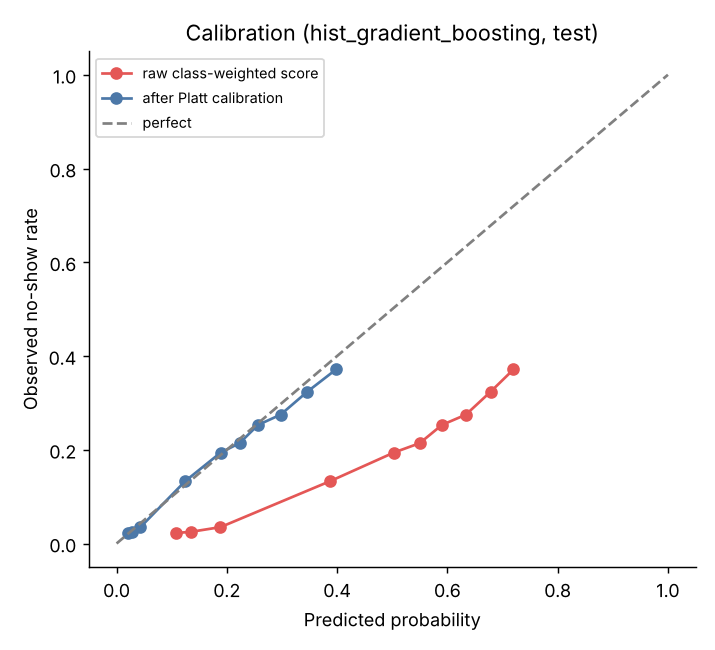

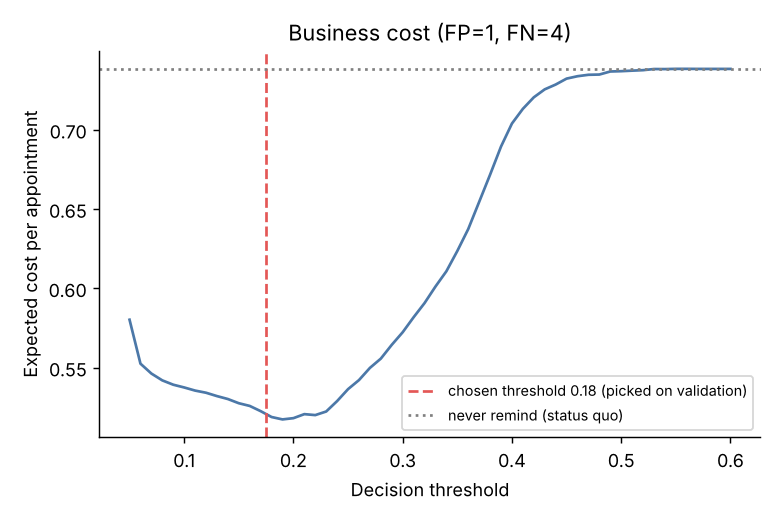

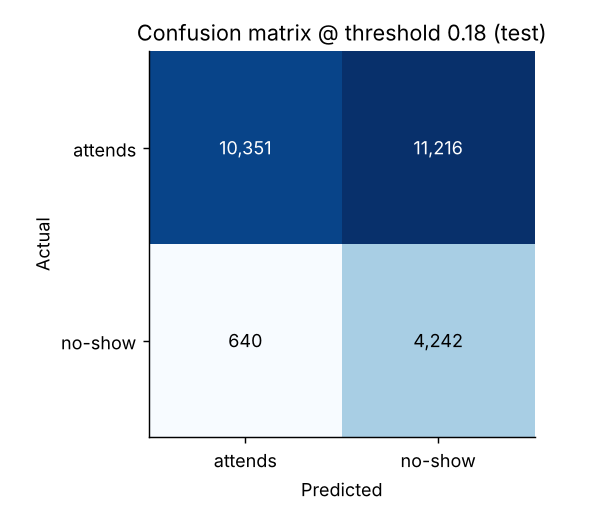

In [9]:
display(Image(str(config.FIG_DIR/'06_calibration.png'))); display(Image(str(config.FIG_DIR/'07_cost_vs_threshold.png'))); display(Image(str(config.FIG_DIR/'08_confusion_matrix.png')))

In [10]:
pd.DataFrame(m['threshold_sweep_test']).set_index('threshold')[['precision','recall','f1','flag_rate','fp','fn','cost_per_appointment']]

,precision,recall,f1,flag_rate,fp,fn,cost_per_appointment
threshold,,,,,,,
0.10,0.2598,0.9459,0.4076,0.6721,13159,264,0.5374
0.15,0.2667,0.9134,0.4129,0.6321,12260,423,0.5275
0.20,0.2847,0.8019,0.4202,0.5199,9835,967,0.5181
0.25,0.3102,0.6157,0.4126,0.3663,6683,1876,0.5364
0.30,0.3360,0.4445,0.3827,0.2442,4288,2712,0.5723
0.35,0.3591,0.2808,0.3152,0.1444,2447,3511,0.6235
0.40,0.4185,0.0715,0.1221,0.0315,485,4533,0.7039
0.50,0.5455,0.0025,0.0049,0.0008,10,4870,0.7369


## 6. Explainability, subgroups and error analysis

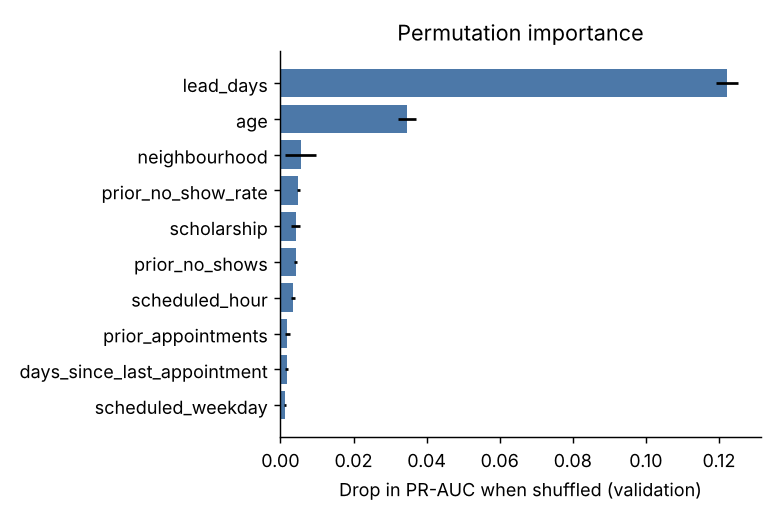

,label,low,high,n_validation,observed_no_show_rate_validation
0,very low,0.00,0.10,7038,0.0327
1,low,0.10,0.20,2053,0.1754
2,medium,0.20,0.30,5467,0.2524
3,high,0.30,0.45,5815,0.3591
4,very high,0.45,1.00,165,0.4000


In [11]:
display(Image(str(config.FIG_DIR/'09_permutation_importance.png'))); pd.DataFrame(m['risk_bands_validation'])

In [12]:
for k,v in m['subgroup_audit_test'].items():
    print(k); display(pd.DataFrame(v).set_index('group'))

gender


,n,observed_no_show_rate,mean_predicted_probability,flag_rate,recall,precision
group,,,,,,
F,17314,0.1828,0.1945,0.5917,0.8736,0.2699
M,9135,0.1880,0.1891,0.5708,0.8602,0.2833


age_group


,n,observed_no_show_rate,mean_predicted_probability,flag_rate,recall,precision
group,,,,,,
0-17,6498,0.2011,0.2184,0.6180,0.9304,0.3028
18-34,5584,0.2233,0.2274,0.6531,0.9479,0.3241
35-64,10743,0.1675,0.1767,0.5839,0.8510,0.2441
65+,3624,0.1460,0.1402,0.4200,0.5917,0.2057


scholarship


,n,observed_no_show_rate,mean_predicted_probability,flag_rate,recall,precision
group,,,,,,
0,23888,0.1819,0.1893,0.5814,0.8608,0.2694
1,2561,0.2093,0.2236,0.6130,0.9347,0.3191


In [13]:
# Error analysis: false negatives (missed no-shows) vs true positives, on the test set at the operating threshold
import joblib; from noshow import predict
art = joblib.load(config.MODEL_PATH); te = df[df.split=='test'].copy()
te['p'] = art['calibrator'].predict(art['pipeline'].predict_proba(te[config.FEATURES])[:,1]); te['flag']=(te.p>=art['threshold']).astype(int)
fn = te[(te.no_show==1)&(te.flag==0)]; tp = te[(te.no_show==1)&(te.flag==1)]
cols=['lead_days','age','prior_appointments','has_history','same_day','scholarship']
print(f'missed no-shows: {len(fn)}  caught: {len(tp)}')
pd.DataFrame({'missed (FN)':fn[cols].mean(),'caught (TP)':tp[cols].mean()})

missed no-shows: 640  caught: 4242


,missed (FN),caught (TP)
lead_days,2.307812,18.617633
age,50.945312,32.282650
prior_appointments,2.423437,1.044554
has_history,0.581250,0.393446
same_day,0.426563,0.023574
scholarship,0.054688,0.118105


Missed no-shows are dominated by **same-day / very short-lead bookings** (~43% of misses vs ~2% of caught cases; mean lead ≈ 2 days vs ≈ 19 days) and by **older patients** (mean age ≈ 51 vs ≈ 32). Same-day patients no-show only ~4% of the time, so the model has little signal there, and there is no time to remind them anyway. The age skew explains the low recall for 65+ in the subgroup audit.